# Standard blocks

The ready-made blocks, start to end: sources, a DSP chain with spectra,
filters, I/Q down-conversion, a control loop, probes and a chunking test.
Each result is checked against theory or a SciPy one-shot reference.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.signal as sig

import sigline as sl

fs = 48_000.0

## 1. Sources

All sources are `Source` subclasses: a sample counter and `generate(n)`.
Deterministic ones on the left, random ones on the right; each random
source takes a `seed`, so a run repeats exactly.

In [2]:
scopes = {
    "Step(0.5 ms)": sl.Step(0.5e-3),
    "Noise(0.3)": sl.Noise(0.3, seed=1),
    "Sine(2 kHz)": sl.Sine(2e3),
    "RandomBits()": sl.RandomBits(seed=1),
    "Chirp(0, 4 MHz/s)": sl.Chirp(0.0, rate=4e6),
    "RandomPulses(2 kHz, 0.1 ms)": sl.RandomPulses(2e3, duration=1e-4, seed=2),
    "Pulses(0.2 ms, 0.5 ms)": sl.Pulses(0.2e-3, 0.5e-3),
    "MarkovChain(3 states)": sl.MarkovChain(
        [[0.9, 0.1, 0.0], [0.0, 0.9, 0.1], [0.1, 0.0, 0.9]], seed=3
    ),
    "Signal(t² envelope)": sl.Signal(lambda t: (t / 2e-3) ** 2),
}
for label, src in scopes.items():
    src >> sl.Scope(label)
d = sl.Diagram(*scopes.values(), fs=fs)

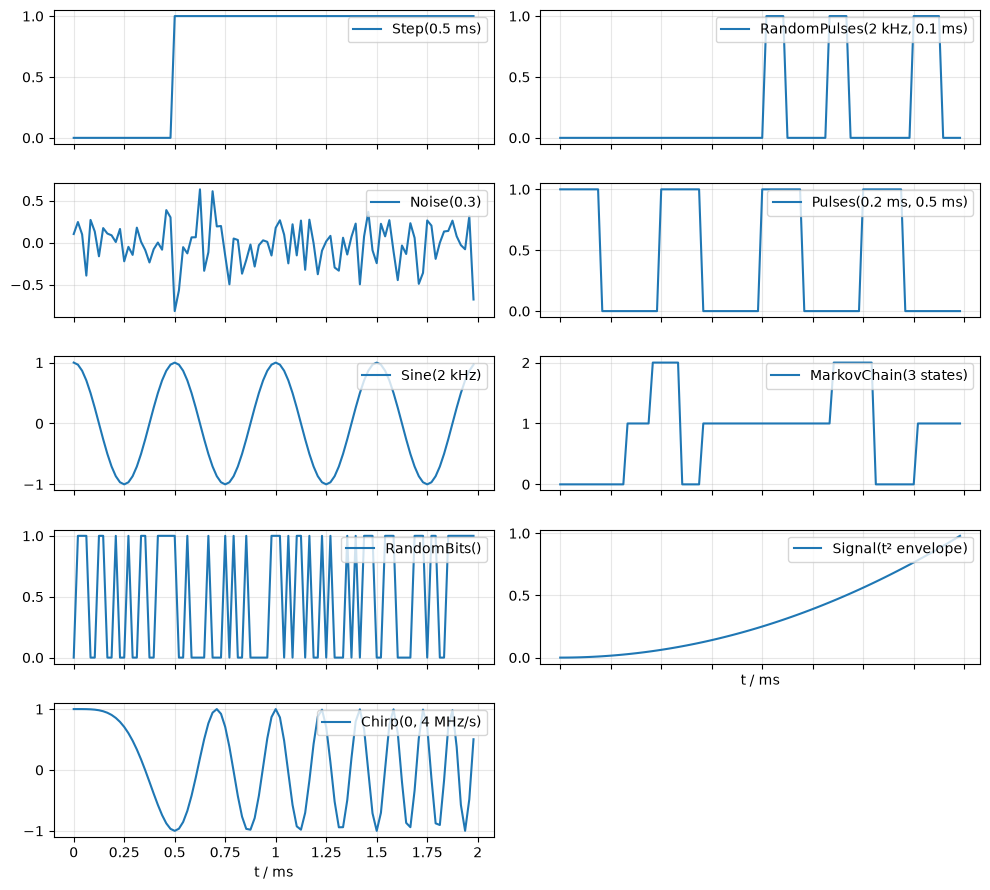

In [3]:
d.run(2e-3)
fig, grid = plt.subplots(5, 2, figsize=(10, 9), sharex=True)
d.plot(axes=grid.T.flat[:9])
grid[-1, 1].axis("off")
for ax in grid.flat:
    ax.xaxis.set_major_formatter(lambda t, _: f"{1e3 * t:g}")
    ax.set_xlabel("")
grid[-1, 0].set_xlabel("t / ms")
grid[-2, 1].set_xlabel("t / ms")
fig.tight_layout()
plt.show()

## 2. A DSP chain

Two tones and noise, low-pass, then mixed up by 5 kHz. `d.probe` records the
filter input without a line to a Scope.

In [4]:
taps = sig.firwin(101, 3e3, fs=fs)
add, lp, mix, out = sl.Sum("+++"), sl.FIR(taps), sl.mixer(5e3), sl.Scope("out")
sl.Sine(1e3) >> add["x0"]
sl.Sine(9e3, amp=0.5) >> add["x1"]
sl.Noise(0.05, seed=2) >> add["x2"]
add >> lp >> mix >> sl.Gain(2.0) >> out

d = sl.Diagram(out, fs=fs)
inp = d.probe(add)

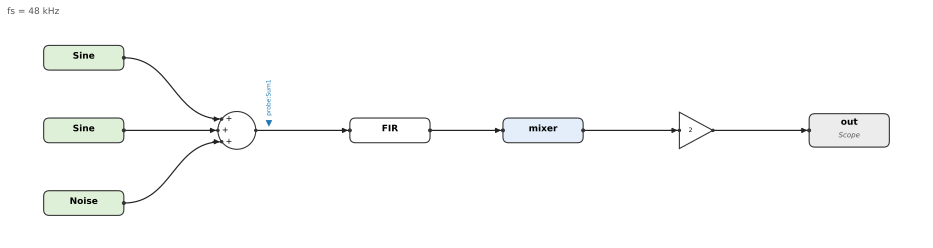

In [5]:
d  # a diagram shows itself as a graph

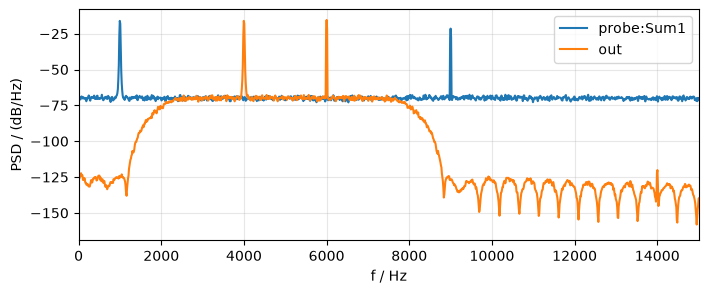

In [6]:
d.run(1.0, chunk=1024)

fig, ax = plt.subplots(figsize=(8, 3))
inp.plot_psd(ax=ax)
out.plot_psd(ax=ax)
ax.set_xlim(0, 15e3)
plt.show()

Reference: the whole record through SciPy in one call.

In [7]:
n = np.arange(d.n)
x = inp.data
ref = 2 * sig.lfilter(taps, 1, x) * np.cos(2 * np.pi * 5e3 * n / fs)
print("max |error| vs one-shot:", np.max(np.abs(out.data - ref)))

max |error| vs one-shot: 1.1908585229036817e-11


### The same chain with operators

Arithmetic on signals adds the blocks: `+` a `Sum`, a number times a signal
a `Gain`. A plain function after `>>` becomes a `FuncChunk`. Same result, fewer
names.

max |difference| to the explicit chain: 0.0


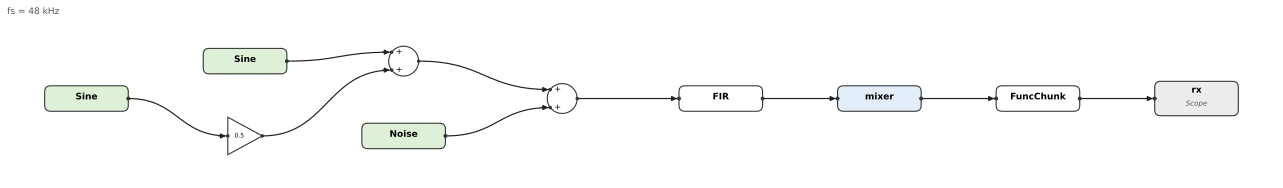

In [8]:
rx = sl.Scope("rx")
x2 = sl.Sine(1e3) + 0.5 * sl.Sine(9e3) + sl.Noise(0.05, seed=2)
x2 >> sl.FIR(taps) >> sl.mixer(5e3) >> (lambda v: 2 * v) >> rx
d2 = sl.Diagram(rx, fs=fs)
d2.run(1.0, chunk=1024)
print("max |difference| to the explicit chain:", np.max(np.abs(rx.data - out.data)))
d2

## 3. Filter attenuation

Measured tone attenuation versus `FIR.freqz`: tone power after / before is
$|H(f)|^2$. A Hann window keeps the 1 kHz tone's leakage out of the 9 kHz
measurement.

1 kHz: measured    0.00 dB, freqz    0.00 dB
9 kHz: measured  -98.04 dB, freqz  -98.04 dB


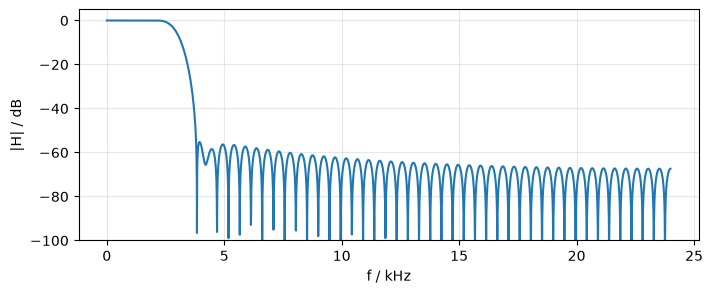

In [9]:
f, H = lp.freqz(n=4096)


def tone_power(scope, f0):
    # windowed projection onto exp(j 2 pi f0 t), after the filter transient
    s = scope.data[1000:]
    t = np.arange(1000, d.n) / fs
    w = np.hanning(len(s))
    return 2 * np.abs(np.sum(w * s * np.exp(-2j * np.pi * f0 * t)) / np.sum(w)) ** 2


filtered = d.probe(lp)
d.reset().run(1.0, chunk=1024)
for f0 in (1e3, 9e3):
    measured = 10 * np.log10(tone_power(filtered, f0) / tone_power(inp, f0))
    _, h = sig.freqz(taps, 1, worN=[f0], fs=fs)
    h_db = 20 * np.log10(abs(h[0]))
    print(f"{f0 / 1e3:.0f} kHz: measured {measured:7.2f} dB, freqz {h_db:7.2f} dB")

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(f / 1e3, 20 * np.log10(np.abs(H) + 1e-12))
ax.set(xlabel="f / kHz", ylabel="|H| / dB", ylim=(-100, 5))
ax.grid(alpha=0.3)
plt.show()

## 4. I/Q down-conversion

A 110 kHz tone, mixed with a 100 kHz cos/sin LO and low-passed, becomes a
10 kHz complex tone. `FuncChunk` joins I and Q.

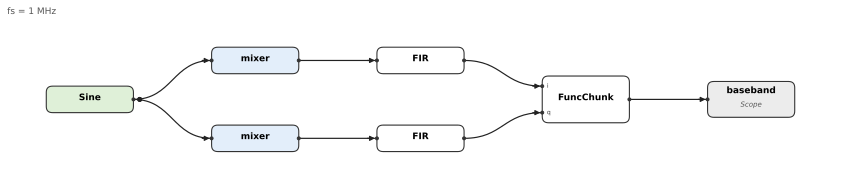

In [10]:
fs_rf = 1e6
rf = sl.Sine(110e3)
i_mix, q_mix = sl.mixer(100e3, "cos"), sl.mixer(100e3, "sin")
taps_iq = sig.firwin(129, 30e3, fs=fs_rf)
iq, bb = sl.FuncChunk(lambda i, q: 2 * (i - 1j * q)), sl.Scope("baseband")
rf >> i_mix >> sl.FIR(taps_iq) >> iq["i"]
rf >> q_mix >> sl.FIR(taps_iq) >> iq["q"]
iq >> bb
d_iq = sl.Diagram(bb, fs=fs_rf)
d_iq

peak at 10.01 kHz


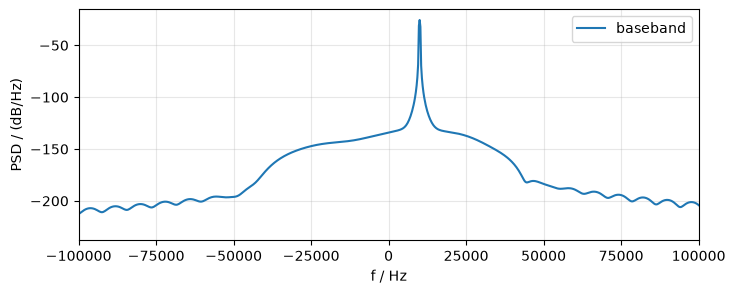

In [11]:
d_iq.run(n=50_000, chunk=4096)

f, P = bb.psd()
print(f"peak at {f[np.argmax(P)] / 1e3:.2f} kHz")
fig, ax = plt.subplots(figsize=(8, 3))
bb.plot_psd(ax=ax)
ax.set_xlim(-100e3, 100e3)
plt.show()

## 5. A control loop

PI controller (`IIR`) driving a first-order plant (`IIR`), with one sample of
loop delay. The loop needs its own output within each chunk, so it runs
sample by sample (`d.loops()`); the step source stays vectorised.

Theory: with $C(z) = \frac{b_0 + b_1 z^{-1}}{1 - z^{-1}}$,
$P(z) = \frac{(1-a)}{1 - a z^{-1}}$ and loop gain $L = C P z^{-1}$, the
closed loop is $T = L / (1 + L)$.

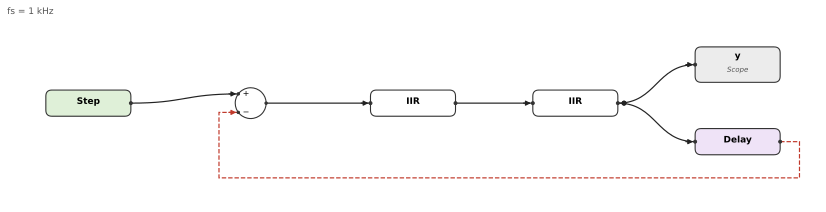

In [12]:
fs_c, kp, ki, a = 1000.0, 0.8, 40.0, 0.95
b_pi, a_pi = [kp + ki / fs_c, -kp], [1.0, -1.0]
b_p, a_p = [1 - a], [1.0, -a]

ref, err, y = sl.Step(), sl.Sum("+-"), sl.Scope("y")
pi, plant = sl.IIR(b=b_pi, a=a_pi), sl.IIR(b=b_p, a=a_p)
ref >> err["x0"]
err >> pi >> plant >> y
plant >> sl.Delay(1) >> err["x1"]
d = sl.Diagram(y, fs=fs_c)
d

Diagram fs=1000 Hz, 6 blocks, chunk=1024
  state  Step2
  loop   loop[Sum4, IIR1, IIR2, Delay1]
  step   y

max |error| vs closed-loop transfer function: 6.661338147750939e-15


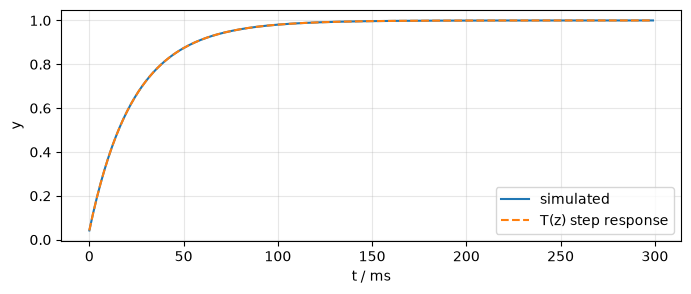

In [13]:
d.run(0.3)
print(d.summary().split("lines:")[0])

# closed loop from polynomials in z^-1
num = np.polymul(np.polymul(b_pi, b_p), [0.0, 1.0])
den = np.polyadd(np.polymul(a_pi, a_p), num)
theory = sig.lfilter(num, den, np.ones(d.n))
print("max |error| vs closed-loop transfer function:", np.max(np.abs(y.data - theory)))

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(1e3 * d.t, y.data, label="simulated")
ax.plot(1e3 * d.t, theory, "--", label="T(z) step response")
ax.set(xlabel="t / ms", ylabel="y")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 6. Testing a block

`assert_chunk_invariant` runs a block in one chunk, after `reset()`, and in
fixed and random chunk sizes. A block that forgets its state fails:

In [14]:
from sigline.testing import assert_chunk_invariant

x = np.random.default_rng(0).standard_normal(500)
assert_chunk_invariant(lambda: sl.IIR(sos=sig.butter(4, 0.2, output="sos")), x)
print("IIR: chunk invariant")


class Forgetful(sl.Block):
    def step(self, x):
        return sig.lfilter([1.0], [1.0, -0.9], x)  # no state kept


try:
    assert_chunk_invariant(Forgetful, x)
except AssertionError as err:
    print(err)

IIR: chunk invariant
after reset(): output 'y' differs from the one-chunk run first at sample 166: 0.08661926298854213 != -1.3205054865525687 (max error 1.57)


## Summary

- Sources: `Const`, `Step`, `Impulse`, `Sine`, `Chirp`, `Pulses`, `Signal`,
  `FromArray`; random: `Noise`, `RandomBits`, `RandomPulses`, `MarkovChain`.
- Operators: `a + b`, `2 * a`, `src >> np.abs` add the blocks.
- Math: `Gain`, `Sum`, `Product`, `FuncChunk`; `Delay`. `mixer` is a `Sine` and
  a `Product`, as a subsystem.
- Filters: `FIR`, `IIR`, with `.freqz()`.
- `Scope`: `.plot()`, `.psd()` (arrays), `.plot_psd()`; `d.probe(...)` records any signal.
- `assert_chunk_invariant` tests your own blocks.